# Notebook 05 - Perbandingan DDS vs noDDS, Metrik, dan SHAP

**Tahap penelitian:** Analisis Hasil.

Notebook ini membandingkan Random Forest, XGBoost, dan LightGBM pada dataset DDS (174 fitur) dan noDDS (164 fitur). Semua model memakai validation set yang sama. Metrik dihitung untuk keenam model; SHAP dihitung pada keenam model dengan sampel validation yang sama untuk mengukur kontribusi DDS dan membandingkan ranking fitur kanonik. Test set tidak digunakan di sini dan dievaluasi di Notebook 07.


## 0. Setup


In [31]:
import sys
import pickle
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')

_root_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _root_candidates if (p / "configs" / "config.yaml").exists() and (p / "src").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root repo (configs/config.yaml dan src/). Jalankan notebook dari repo atau folder notebooks.")
sys.path.insert(0, str(ROOT))

OUT       = ROOT / 'outputs' / 'results'
MODEL_DIR = ROOT / 'outputs' / 'models'
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})
MODEL_COLORS = ['#4472C4', '#ED7D31', '#70AD47']
print('Setup selesai.')


Setup selesai.


## 1. Muat enam model dan pasangan dataset


In [32]:
from src.preprocessing import load_splits

DATASET_DIRS = {'DDS': ROOT / 'data' / 'processed', 'noDDS': ROOT / 'data' / 'processed_no_dds'}
splits_by_dataset = {}
feature_cols_by_dataset = {}
label_encoders = {}
for variant, data_dir in DATASET_DIRS.items():
    train_df, val_df, test_df, cols, label_encoder = load_splits(data_dir)
    splits_by_dataset[variant] = {'train': train_df, 'val': val_df, 'test': test_df}
    feature_cols_by_dataset[variant] = cols
    label_encoders[variant] = label_encoder
    assert len(cols) == (174 if variant == 'DDS' else 164)

identity_cols = ['_source_file', '_room', '_board_number', '_deal_key', 'label', 'matches_par_contract']
for part in ('train', 'val', 'test'):
    assert splits_by_dataset['DDS'][part][identity_cols].equals(
        splits_by_dataset['noDDS'][part][identity_cols]
    ), f'Split atau label berbeda pada {part}'

y_val = splits_by_dataset['noDDS']['val']['label'].to_numpy()
X_val_by_dataset = {
    variant: splits_by_dataset[variant]['val'][feature_cols_by_dataset[variant]].to_numpy(dtype=np.float32)
    for variant in DATASET_DIRS
}
le = label_encoders['noDDS']

model_entries = []
for variant in ('DDS', 'noDDS'):
    suffix = '_dds' if variant == 'DDS' else ''
    for algorithm in ('RandomForest', 'XGBoost', 'LightGBM'):
        path = MODEL_DIR / f'{algorithm.lower()}{suffix}.pkl'
        assert path.exists(), f'Model tidak ditemukan: {path}. Jalankan Notebook 04.'
        with open(path, 'rb') as f:
            model = pickle.load(f)
        model_entries.append({
            'variant': variant,
            'algorithm': algorithm,
            'display_name': f'{algorithm} ({variant})',
            'model': model,
            'features': feature_cols_by_dataset[variant],
            'X_val': X_val_by_dataset[variant],
        })
        print(f'Loaded {algorithm} / {variant}: {len(feature_cols_by_dataset[variant])} fitur')
trained_models = [entry['model'] for entry in model_entries]
MODEL_COLORS = ['#C62828' if e['variant'] == 'DDS' else '#1565C0' for e in model_entries]


Loaded RandomForest / DDS: 174 fitur
Loaded XGBoost / DDS: 174 fitur
Loaded LightGBM / DDS: 174 fitur
Loaded RandomForest / noDDS: 164 fitur
Loaded XGBoost / noDDS: 164 fitur
Loaded LightGBM / noDDS: 164 fitur


## 2. Evaluasi Baseline pada Validation Set


In [33]:
from src.evaluation import evaluate, print_summary, compare_models, save_results

all_val_results = []
predictions = {}
probabilities = {}
for entry in model_entries:
    model = entry['model']
    y_pred = model.predict(entry['X_val'])
    y_proba = model.predict_proba(entry['X_val'])
    result = evaluate(y_val, y_pred, y_proba, le, model_name=entry['display_name'])
    result['dataset_variant'] = entry['variant']
    result['algorithm'] = entry['algorithm']
    all_val_results.append(result)
    predictions[entry['display_name']] = y_pred
    probabilities[entry['display_name']] = y_proba
    save_results(result, OUT / f"nb05_{entry['algorithm'].lower()}_{entry['variant'].lower()}_val.json")
    print_summary(result)



  RandomForest (DDS)
  Accuracy          : 0.8038
  Precision (macro) : 0.7389
  Recall (macro)    : 0.6906
  F1 (macro)        : 0.7075
  F1 (weighted)     : 0.7929
  F1 (positive)     : 0.5396
  ROC-AUC           : 0.7880
  PR-AUC (avg prec) : 0.6094

  XGBoost (DDS)
  Accuracy          : 0.8117
  Precision (macro) : 0.7658
  Recall (macro)    : 0.6748
  F1 (macro)        : 0.6987
  F1 (weighted)     : 0.7925
  F1 (positive)     : 0.5142
  ROC-AUC           : 0.7957
  PR-AUC (avg prec) : 0.6071

  LightGBM (DDS)
  Accuracy          : 0.7923
  Precision (macro) : 0.7221
  Recall (macro)    : 0.7350
  F1 (macro)        : 0.7279
  F1 (weighted)     : 0.7952
  F1 (positive)     : 0.5955
  ROC-AUC           : 0.8121
  PR-AUC (avg prec) : 0.6332

  RandomForest (noDDS)
  Accuracy          : 0.7653
  Precision (macro) : 0.6711
  Recall (macro)    : 0.6170
  F1 (macro)        : 0.6295
  F1 (weighted)     : 0.7436
  F1 (positive)     : 0.4051
  ROC-AUC           : 0.7148
  PR-AUC (avg prec) 

In [34]:
def report_to_df(report_dict):
    rows = {k: v for k, v in report_dict.items() if isinstance(v, dict)}
    df = pd.DataFrame(rows).T
    df['support'] = df['support'].astype(int)
    return df.rename(index={'0': 'Tidak cocok par (0)', '1': 'Cocok par (1)'})

for result in all_val_results:
    print(f"\n{result['model']} - validation:")
    display(report_to_df(result['per_class_report']).round(4))



RandomForest (DDS) - validation:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8405,0.9133,0.8754,5683
Cocok par (1),0.6372,0.4679,0.5396,1851
macro avg,0.7389,0.6906,0.7075,7534
weighted avg,0.7905,0.8038,0.7929,7534



XGBoost (DDS) - validation:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8298,0.9439,0.8832,5683
Cocok par (1),0.7019,0.4057,0.5142,1851
macro avg,0.7658,0.6748,0.6987,7534
weighted avg,0.7984,0.8117,0.7925,7534



LightGBM (DDS) - validation:


...

,precision,recall,f1-score,support
Tidak cocok par (0),0.8052,0.9087,0.8538,5683
Cocok par (1),0.5370,0.3252,0.4051,1851
macro avg,0.6711,0.6170,0.6295,7534
weighted avg,0.7393,0.7653,0.7436,7534



XGBoost (noDDS) - validation:


,precision,recall,f1-score,support
Tidak cocok par (0),0.7835,0.9627,0.8639,5683
Cocok par (1),0.6152,0.1831,0.2823,1851
macro avg,0.6994,0.5729,0.5731,7534
weighted avg,0.7421,0.7712,0.7210,7534



LightGBM (noDDS) - validation:


,precision,recall,f1-score,support
Tidak cocok par (0),0.8326,0.7892,0.8103,5683
Cocok par (1),0.4420,0.5127,0.4747,1851
macro avg,0.6373,0.6509,0.6425,7534
weighted avg,0.7366,0.7213,0.7279,7534


In [35]:
val_df = compare_models(all_val_results)
val_df.to_csv(OUT / 'nb05_val_comparison.csv')
print('Perbandingan enam baseline pada validation set (split yang sama):')
display(val_df.style
    .format('{:.4f}')
    .highlight_max(color='#C8E6C9', axis=0)
    .set_caption('DDS 174 fitur vs noDDS 164 fitur; hijau = nilai tertinggi per metrik'))


Perbandingan enam baseline pada validation set (split yang sama):


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,f1_positive,roc_auc,average_precision
model,,,,,,,,
RandomForest (DDS),0.8038,0.7389,0.6906,0.7075,0.7929,0.5396,0.7880,0.6094
XGBoost (DDS),0.8117,0.7658,0.6748,0.6987,0.7925,0.5142,0.7957,0.6071
LightGBM (DDS),0.7923,0.7221,0.7350,0.7279,0.7952,0.5955,0.8121,0.6332
RandomForest (noDDS),0.7653,0.6711,0.6170,0.6295,0.7436,0.4051,0.7148,0.4704
XGBoost (noDDS),0.7712,0.6994,0.5729,0.5731,0.7210,0.2823,0.7115,0.4665
LightGBM (noDDS),0.7213,0.6373,0.6509,0.6425,0.7279,0.4747,0.7126,0.4590


## 3. Confusion matrix keenam model


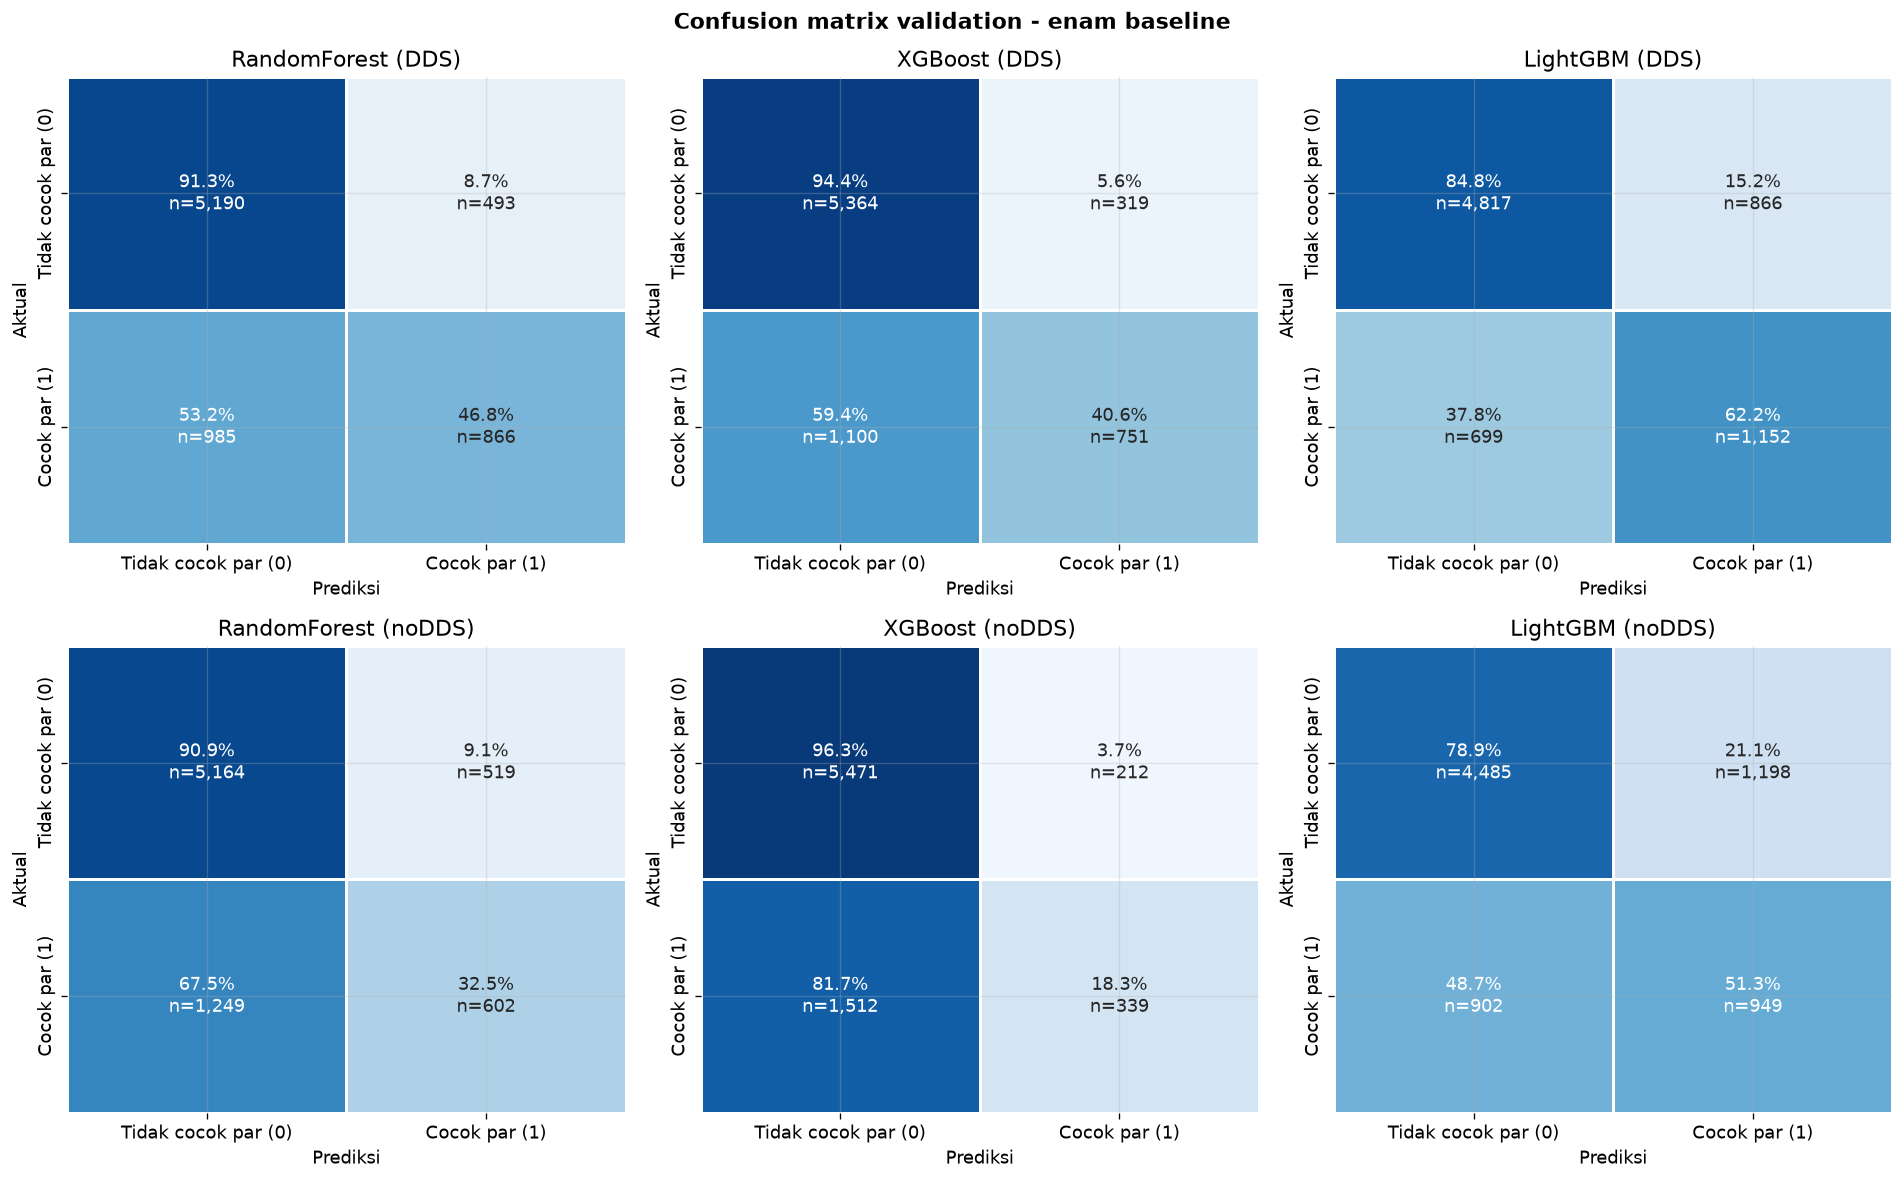

In [36]:
from sklearn.metrics import confusion_matrix

class_names = ['Tidak cocok par (0)', 'Cocok par (1)']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, entry in zip(axes.flat, model_entries):
    y_pred = predictions[entry['display_name']]
    matrix = confusion_matrix(y_val, y_pred, labels=[0, 1])
    row_totals = matrix.sum(axis=1, keepdims=True)
    matrix_pct = np.divide(matrix * 100.0, row_totals,
                           out=np.zeros_like(matrix, dtype=float), where=row_totals != 0)
    labels = np.array([[f'{matrix_pct[r,c]:.1f}%\nn={matrix[r,c]:,}' for c in range(2)] for r in range(2)])
    sns.heatmap(matrix_pct, annot=labels, fmt='', cmap='Blues', vmin=0, vmax=100,
                xticklabels=class_names, yticklabels=class_names, cbar=False,
                linewidths=0.8, linecolor='white', ax=ax)
    ax.set_title(entry['display_name'])
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
fig.suptitle('Confusion matrix validation - enam baseline', fontweight='bold')
fig.tight_layout()
fig.savefig(OUT / 'nb05_confusion_matrix_comparison.png', bbox_inches='tight', dpi=160)
plt.show()


## 4. Precision, recall, dan F1 per kelas


In [ ]:
from sklearn.metrics import precision_recall_fscore_support

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
metric_names = ['Precision', 'Recall', 'F1']
for class_id, (ax, class_name) in enumerate(zip(axes, class_names)):
    x = np.arange(len(metric_names))
    width = 0.13
    for j, entry in enumerate(model_entries):
        p, r, f1, _ = precision_recall_fscore_support(
            y_val, predictions[entry['display_name']], labels=[0, 1], zero_division=0
        )
        values = [p[class_id], r[class_id], f1[class_id]]
        ax.bar(x + (j - 2.5) * width, values, width,
               color=MODEL_COLORS[j], alpha=0.8, label=entry['display_name'])
    ax.set_xticks(x)
    ax.set_xticklabels(metric_names)
    ax.set_title(class_name)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7, ncol=2)
fig.suptitle('Precision / Recall / F1 per kelas - validation')
fig.tight_layout()
fig.savefig(OUT / 'nb05_per_class_comparison.png', bbox_inches='tight', dpi=150)
plt.show()


## 5. Feature importance sebagai pembanding awal


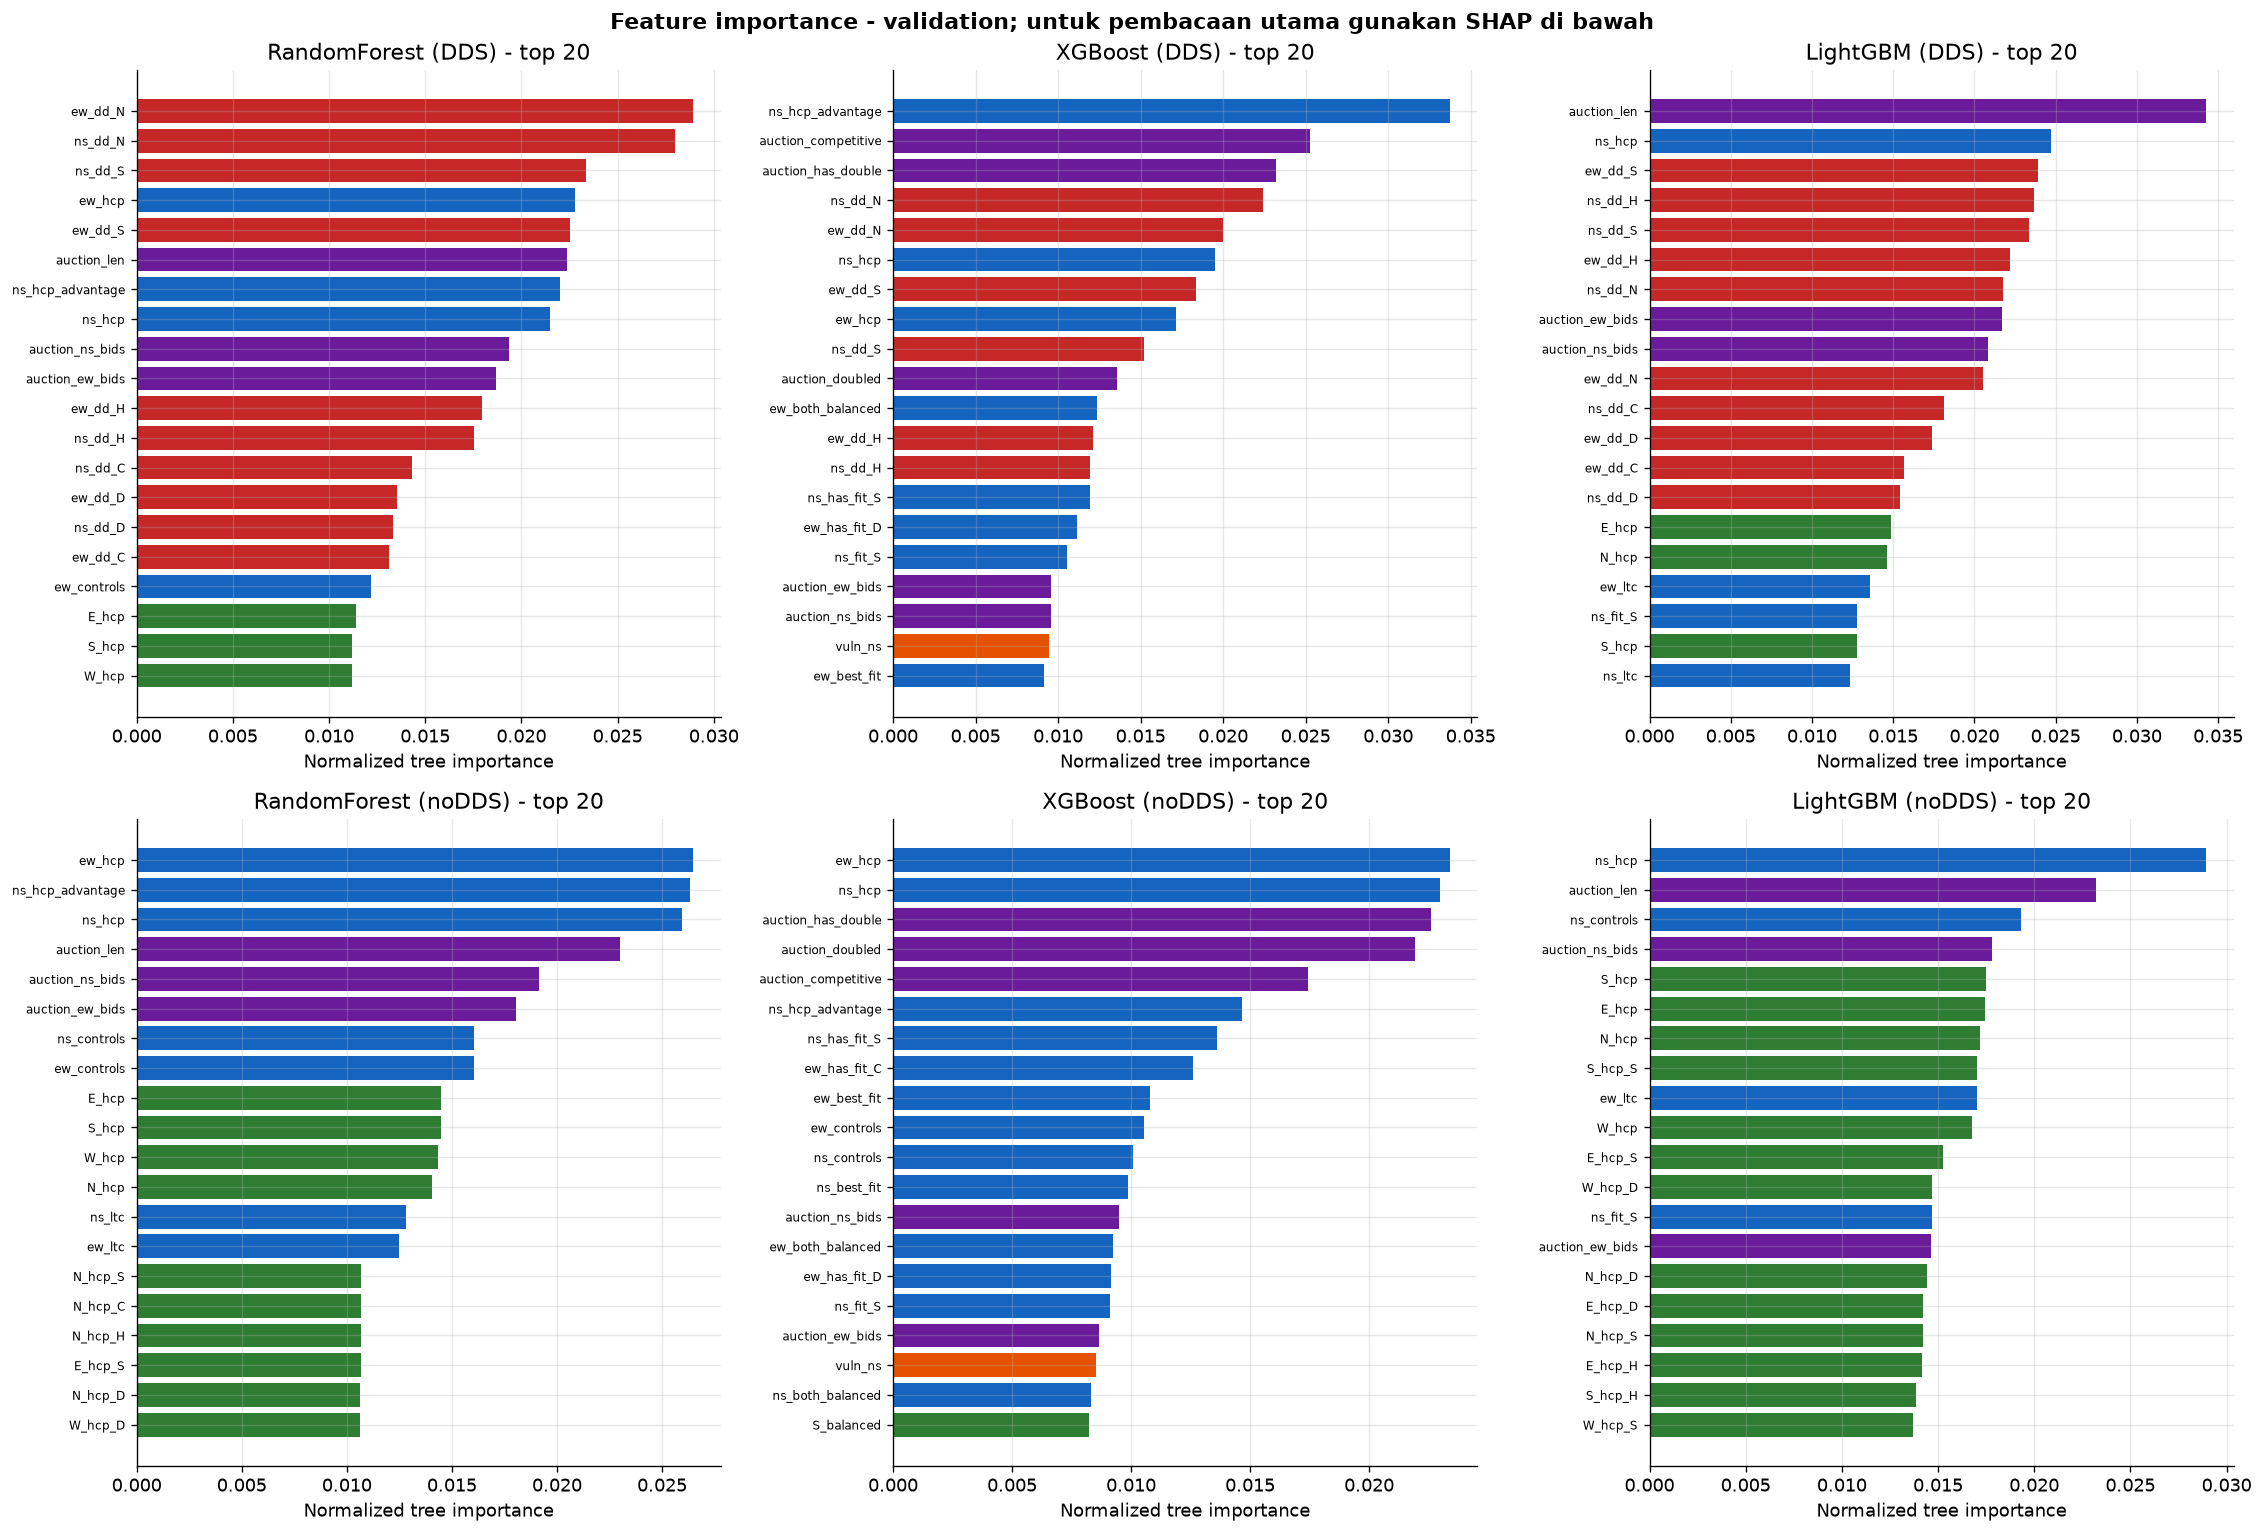

In [ ]:
N_TOP = 20

def feat_group_color(name):
    if name.startswith(('ns_dd_', 'ew_dd_')):
        return '#C62828'
    if name.startswith(('ns_', 'ew_')):
        return '#1565C0'
    if len(name) >= 2 and name[0] in 'NESW' and name[1] == '_':
        return '#2E7D32'
    if name.startswith(('dealer_', 'vuln_')):
        return '#E65100'
    return '#6A1B9A'

fig, axes = plt.subplots(2, 3, figsize=(19, 13))
for ax, entry in zip(axes.flat, model_entries):
    importance = np.asarray(entry['model'].feature_importances(), dtype=float)
    importance /= importance.sum()
    top = np.argsort(importance)[::-1][:N_TOP]
    names = [entry['features'][i] for i in top]
    values = importance[top]
    ax.barh(range(len(top)), values[::-1],
            color=[feat_group_color(n) for n in names[::-1]])
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(names[::-1], fontsize=7)
    ax.set_title(f"{entry['display_name']} - top {N_TOP}")
    ax.set_xlabel('Normalized tree importance')
fig.suptitle('Feature importance - validation; untuk pembacaan utama gunakan SHAP di bawah', fontweight='bold')
fig.tight_layout()
fig.savefig(OUT / 'nb05_feature_importance_comparison.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
# Konsistensi fitur top-20 antar algoritma dihitung terpisah untuk tiap dataset.
for variant in ('DDS', 'noDDS'):
    entries = [e for e in model_entries if e['variant'] == variant]
    top_sets = []
    for entry in entries:
        values = np.asarray(entry['model'].feature_importances(), dtype=float)
        top = np.argsort(values)[::-1][:N_TOP]
        top_sets.append({entry['features'][i] for i in top})
    shared = set.intersection(*top_sets)
    print(f'{variant}: {len(shared)} fitur masuk top-{N_TOP} di ketiga algoritma: {sorted(shared)}')


DDS: 9 fitur masuk top-20 di ketiga algoritma: ['auction_ew_bids', 'auction_ns_bids', 'ew_dd_H', 'ew_dd_N', 'ew_dd_S', 'ns_dd_H', 'ns_dd_N', 'ns_dd_S', 'ns_hcp']
noDDS: 4 fitur masuk top-20 di ketiga algoritma: ['auction_ew_bids', 'auction_ns_bids', 'ns_controls', 'ns_hcp']


## 6. Analisis SHAP berpasangan DDS dan noDDS

SHAP dihitung pada sampel validation berstrata yang sama (200 board) untuk keenam model. Random Forest dan XGBoost memakai SHAP aproksimasi; LightGBM memakai kontribusi pohon native. Porsi mean |SHAP| fitur trik DDS dihitung pada model DDS. Perbandingan ranking fitur kanonik memakai fitur yang sama pada DDS dan noDDS. SHAP menjelaskan kontribusi model, bukan hubungan kausal.

In [ ]:
try:
    import shap
    SHAP_OK = True
    print(f'SHAP {shap.__version__} tersedia.')
except ImportError:
    SHAP_OK = False
    print('SHAP tidak tersedia; install dengan pip install shap untuk interpretasi fitur.')


SHAP 0.52.0 tersedia.


In [ ]:
# Gunakan board validation yang sama untuk seluruh model DDS dan noDDS.
shap_values_by_model = {}
X_shap_by_model = {}
SHAP_SAMPLE_SIZE = 200
shap_model_entries = list(model_entries)

def positive_class_shap(explainer, X, approximate):
    raw = explainer.shap_values(X, approximate=approximate)
    if isinstance(raw, list):
        values = np.asarray(raw[1] if len(raw) > 1 else raw[0])
    else:
        values = np.asarray(raw)
        if values.ndim == 3:
            values = values[:, :, 1] if values.shape[0] == len(X) else values[1]
    if values.ndim != 2:
        raise ValueError(f'Bentuk SHAP tak terduga: {values.shape}')
    return values

if SHAP_OK:
    from sklearn.model_selection import train_test_split
    shap_indices, _ = train_test_split(
        np.arange(len(y_val)), train_size=min(SHAP_SAMPLE_SIZE, len(y_val)),
        stratify=y_val, random_state=42,
    )
    for entry in shap_model_entries:
        sample = entry['X_val'][shap_indices]
        explainer = shap.TreeExplainer(entry['model'].clf)
        values = positive_class_shap(explainer, sample, approximate=(entry['algorithm'] != 'LightGBM'))
        shap_values_by_model[entry['display_name']] = values
        X_shap_by_model[entry['display_name']] = sample
        print(f"{entry['display_name']}: SHAP {values.shape}")


RandomForest (DDS): SHAP (200, 174)


XGBoost (DDS): SHAP (200, 174)


LightGBM (DDS): SHAP (200, 174)


RandomForest (noDDS): SHAP (200, 164)
XGBoost (noDDS): SHAP (200, 164)


LightGBM (noDDS): SHAP (200, 164)


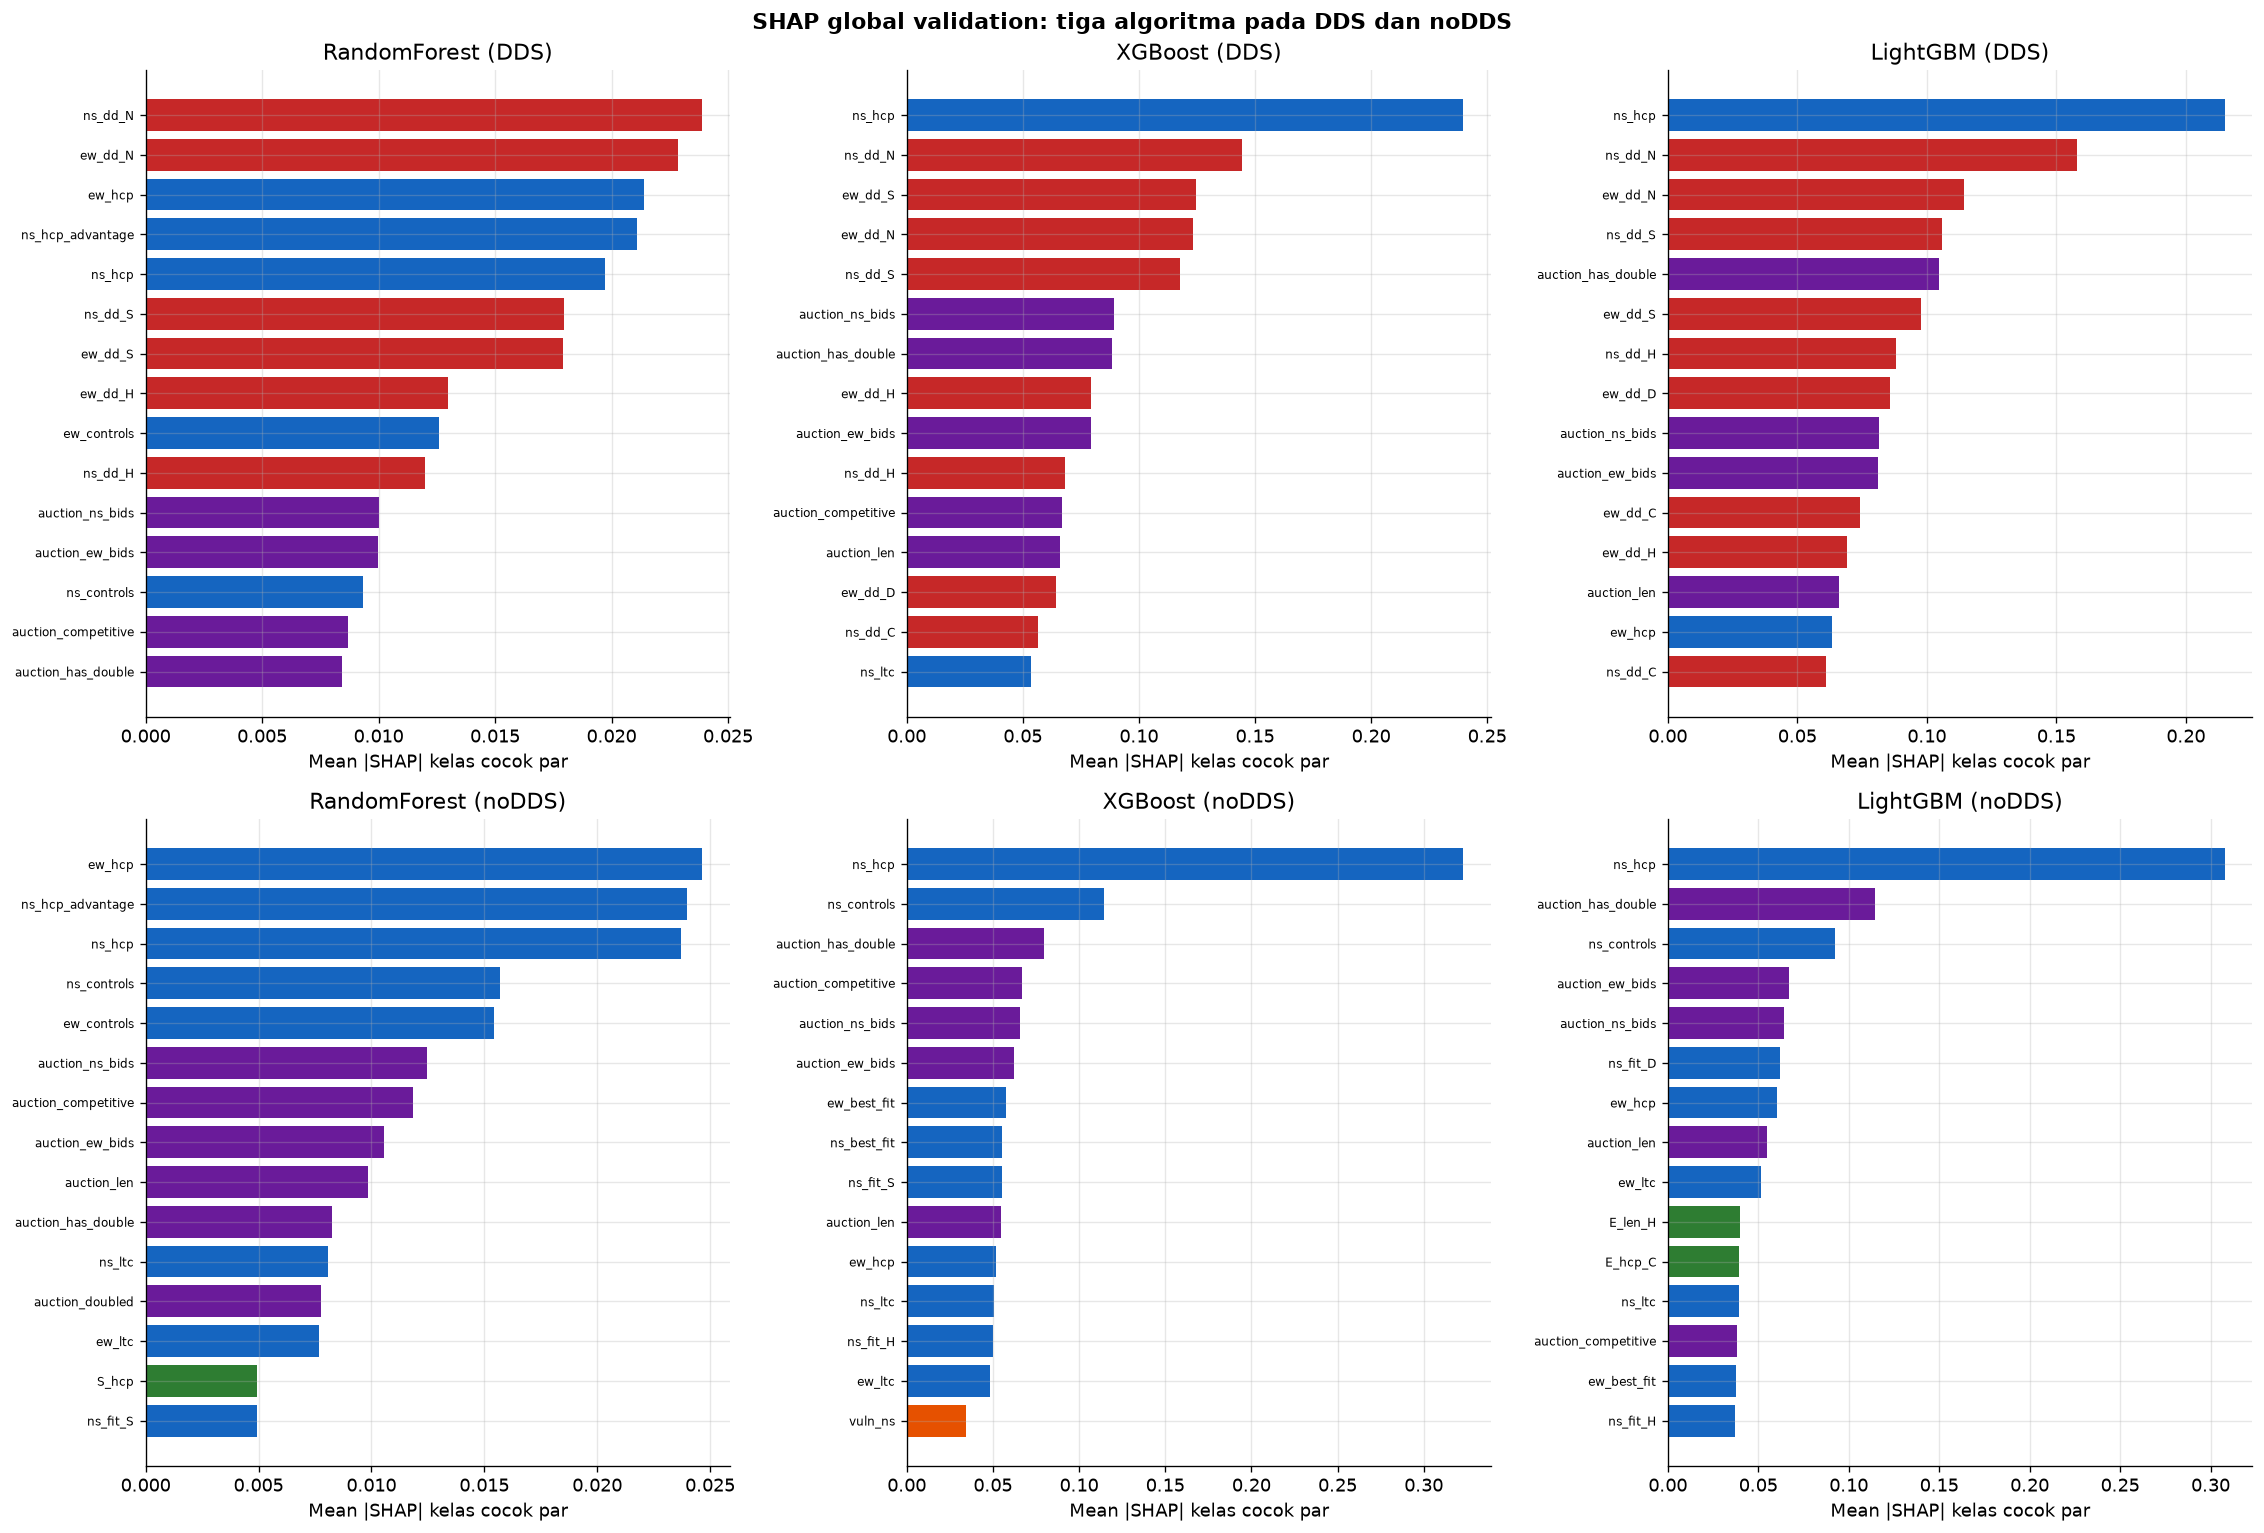

,Algoritma,Dataset,Sampel validation,Metode SHAP,Porsi total mean |SHAP| dari fitur DDS,Fitur trik DDS teratas
0,RandomForest,DDS,200,Approximate Saabas,24.17%,"ns_dd_N, ew_dd_N, ns_dd_S"
1,XGBoost,DDS,200,Approximate Saabas,26.84%,"ns_dd_N, ew_dd_S, ew_dd_N"
2,LightGBM,DDS,200,Exact LightGBM native,30.18%,"ns_dd_N, ew_dd_N, ns_dd_S"
3,RandomForest,noDDS,200,Approximate Saabas,0.00%,Tidak ada pada noDDS
4,XGBoost,noDDS,200,Approximate Saabas,0.00%,Tidak ada pada noDDS
5,LightGBM,noDDS,200,Exact LightGBM native,0.00%,Tidak ada pada noDDS


,Algoritma,Jumlah fitur kanonik dibandingkan,Spearman ranking mean |SHAP| DDS vs noDDS,Irisan top-20 fitur kanonik,Top-20 DDS saja,Top-20 noDDS saja
0,RandomForest,164,0.965,19,ew_fit_H,E_hcp
1,XGBoost,164,0.924,18,"N_hcp_C, W_hcp","E_len_C, ns_fit_D"
2,LightGBM,164,0.876,16,"E_hcp, W_hcp, opening_level, vuln_ew","E_hcp_C, N_hcp_C, ns_best_fit, ns_fit_C"


In [ ]:
if SHAP_OK:
    fig, axes = plt.subplots(2, 3, figsize=(19, 13))
    contribution_rows = []
    shap_effect_rows = []
    for ax, entry in zip(axes.flat, shap_model_entries):
        key = entry['display_name']
        values = shap_values_by_model[key]
        mean_abs = np.abs(values).mean(axis=0)
        mean_abs_by_key = mean_abs
        top = np.argsort(mean_abs)[::-1][:15]
        names = [entry['features'][i] for i in top]
        scores = mean_abs[top]
        ax.barh(range(len(top)), scores[::-1], color=[feat_group_color(n) for n in names[::-1]])
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(names[::-1], fontsize=7)
        ax.set_title(key)
        ax.set_xlabel('Mean |SHAP| kelas cocok par')

        dds_mask = np.array([name.startswith(('ns_dd_', 'ew_dd_')) for name in entry['features']])
        dds_importance = mean_abs[dds_mask]
        dds_names = np.asarray(entry['features'])[dds_mask]
        dds_order = np.argsort(dds_importance)[::-1]
        row = {
            'Algoritma': entry['algorithm'],
            'Dataset': entry['variant'],
            'Sampel validation': len(values),
            'Metode SHAP': 'Approximate Saabas' if entry['algorithm'] != 'LightGBM' else 'Exact LightGBM native',
            'Porsi total mean |SHAP| dari fitur DDS': float(dds_importance.sum() / mean_abs.sum()),
            'Fitur trik DDS teratas': ', '.join(dds_names[dds_order[:3]]) if len(dds_names) else 'Tidak ada pada noDDS',
        }
        contribution_rows.append(row)
        if entry['variant'] == 'DDS':
            shap_effect_rows.append(row)

    fig.suptitle('SHAP global validation: tiga algoritma pada DDS dan noDDS', fontweight='bold')
    fig.tight_layout()
    fig.savefig(OUT / 'nb05_shap_dds_vs_nodds_global.png', bbox_inches='tight', dpi=160)
    plt.show()

    contribution_df = pd.DataFrame(contribution_rows)
    contribution_df.to_csv(OUT / 'nb05_shap_dataset_contributions.csv', index=False)
    display(contribution_df.style.format({'Porsi total mean |SHAP| dari fitur DDS': '{:.2%}'}))

    paired_shap_rows = []
    for algorithm in ('RandomForest', 'XGBoost', 'LightGBM'):
        dds_entry = next(e for e in shap_model_entries if e['algorithm'] == algorithm and e['variant'] == 'DDS')
        nodds_entry = next(e for e in shap_model_entries if e['algorithm'] == algorithm and e['variant'] == 'noDDS')
        dds_abs = pd.Series(np.abs(shap_values_by_model[dds_entry['display_name']]).mean(axis=0), index=dds_entry['features'])
        nodds_abs = pd.Series(np.abs(shap_values_by_model[nodds_entry['display_name']]).mean(axis=0), index=nodds_entry['features'])
        common = sorted(set(dds_abs.index).intersection(nodds_abs.index))
        dds_common = dds_abs.loc[common]
        nodds_common = nodds_abs.loc[common]
        dds_top20 = set(dds_common.nlargest(20).index)
        nodds_top20 = set(nodds_common.nlargest(20).index)
        paired_shap_rows.append({
            'Algoritma': algorithm,
            'Jumlah fitur kanonik dibandingkan': len(common),
            'Spearman ranking mean |SHAP| DDS vs noDDS': float(dds_common.corr(nodds_common, method='spearman')),
            'Irisan top-20 fitur kanonik': len(dds_top20 & nodds_top20),
            'Top-20 DDS saja': ', '.join(sorted(dds_top20 - nodds_top20)),
            'Top-20 noDDS saja': ', '.join(sorted(nodds_top20 - dds_top20)),
        })
    paired_shap_df = pd.DataFrame(paired_shap_rows)
    paired_shap_df.to_csv(OUT / 'nb05_shap_dds_vs_nodds.csv', index=False)
    display(paired_shap_df.style.format({'Spearman ranking mean |SHAP| DDS vs noDDS': '{:.3f}'}))

    shap_effect_df = pd.DataFrame(shap_effect_rows)
    shap_effect_df.to_csv(OUT / 'nb05_shap_dds_effect.csv', index=False)
else:
    contribution_df = pd.DataFrame()
    paired_shap_df = pd.DataFrame()
    shap_effect_df = pd.DataFrame()


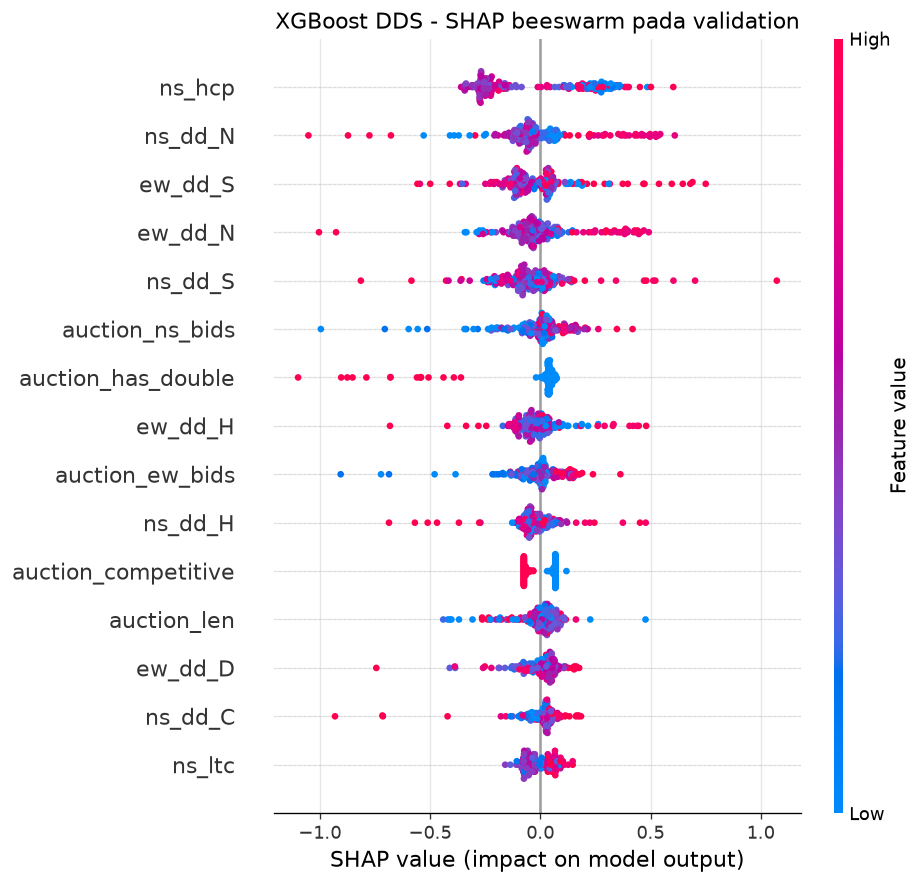

In [ ]:
if SHAP_OK:
    entry = next(e for e in shap_model_entries if e['algorithm'] == 'XGBoost')
    key = entry['display_name']
    values = shap_values_by_model[key]
    top = np.argsort(np.abs(values).mean(axis=0))[::-1][:15]
    plt.figure(figsize=(10, 7))
    shap.summary_plot(values[:, top], X_shap_by_model[key][:, top],
                      feature_names=[entry['features'][i] for i in top],
                      show=False, max_display=15)
    plt.title('XGBoost DDS - SHAP beeswarm pada validation')
    plt.tight_layout()
    plt.savefig(OUT / 'nb05_shap_xgboost_dds_beeswarm.png', bbox_inches='tight', dpi=150)
    plt.show()


## 7. Perbandingan metrik validation dan ringkasan


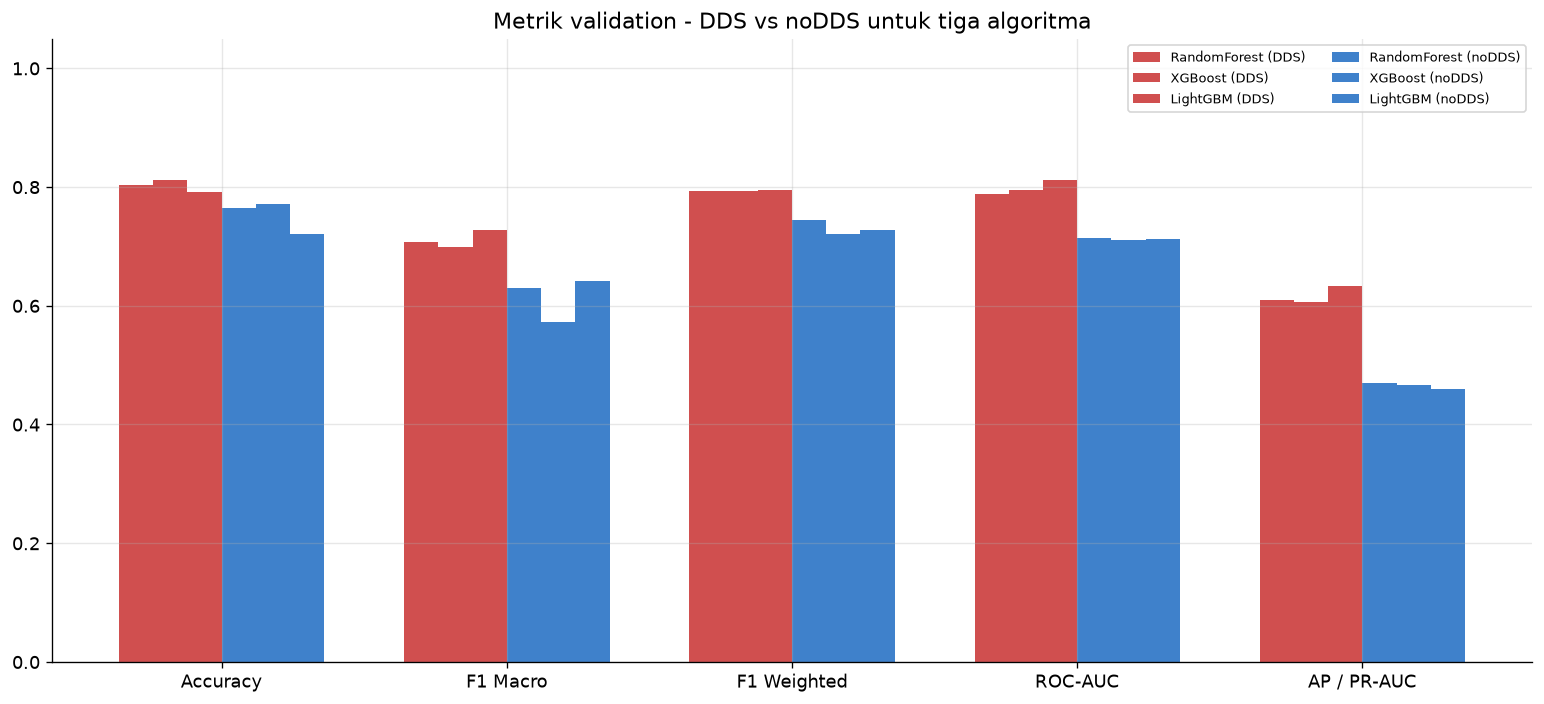

In [ ]:
metric_cols = ['accuracy', 'f1_macro', 'f1_weighted', 'roc_auc', 'average_precision']
metric_labels = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'ROC-AUC', 'AP / PR-AUC']
x = np.arange(len(metric_cols))
width = 0.12
fig, ax = plt.subplots(figsize=(13, 6))
for j, result in enumerate(all_val_results):
    vals = [result.get(k, 0) for k in metric_cols]
    ax.bar(x + (j - 2.5) * width, vals, width,
           color=MODEL_COLORS[j], alpha=0.82, label=result['model'])
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.05)
ax.set_title('Metrik validation - DDS vs noDDS untuk tiga algoritma')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(OUT / 'nb05_metrics_dds_vs_nodds.png', bbox_inches='tight', dpi=150)
plt.show()


In [ ]:
import json

summary = {
    'dataset': {
        'n_total': int(len(splits_by_dataset['noDDS']['train']) + len(splits_by_dataset['noDDS']['val']) + len(splits_by_dataset['noDDS']['test'])),
        'n_train': int(len(splits_by_dataset['noDDS']['train'])),
        'n_val': int(len(splits_by_dataset['noDDS']['val'])),
        'n_test': int(len(splits_by_dataset['noDDS']['test'])),
        'positive_rate_validation': float(y_val.mean()),
        'features': {k: len(v) for k, v in feature_cols_by_dataset.items()},
    },
    'primary_metric': 'average_precision on validation',
    'validation_results': [
        {k: v for k, v in result.items() if k not in ('per_class_report', 'confusion_matrix', 'class_names')}
        for result in all_val_results
    ],
    'shap_dds_effect': shap_effect_rows if SHAP_OK else None,
    'shap_dataset_contributions': contribution_rows if SHAP_OK else None,
    'shap_dds_vs_nodds_common_feature_comparison': paired_shap_rows if SHAP_OK else None,
}
(OUT / 'nb05_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print('Ringkasan enam baseline dan analisis SHAP disimpan. Test set tetap tidak disentuh.')


Ringkasan enam baseline dan analisis SHAP disimpan. Test set tetap tidak disentuh.


## Ringkasan dan Tahap Berikutnya
Gunakan AP validation sebagai metrik utama dan baca SHAP bersama perbandingan kinerja. Perubahan kontribusi 10 fitur trik DDS dapat diperiksa per algoritma; hasil test keenam baseline disajikan di Notebook 07.
